# 日本語のワードクラウドを作る

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/07_corpus_statistics/wordcloud_ja.ipynb)

NLP クックブック 07-04 ／ コーパスの統計と可視化

テキストの頻出語をワードクラウドで可視化したい。

In [1]:
!pip install -q wordcloud fugashi unidic-lite matplotlib-fontja

In [2]:
import io, re, urllib.request, zipfile
from collections import Counter
from fugashi import Tagger

def aozora(url):
    with urllib.request.urlopen(url) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    text = z.read(z.namelist()[0]).decode("cp932")
    text = re.split(r"-{50,}", text)[2].split("底本：")[0]
    return re.sub(r"《.+?》|［＃.+?］|｜", "", text).replace("\r\n", "\n").strip()

text = aozora("https://www.aozora.gr.jp/cards/000081/files/456_ruby_145.zip")  # 銀河鉄道の夜
tagger = Tagger()
stop = {"よう", "こと", "もの", "それ", "これ", "そこ", "どこ", "なに", "ところ", "とき", "うち", "ほう"}
freq = Counter(w.surface for line in text.split("\n") for w in tagger(line)
               if w.feature.pos1 == "名詞" and w.feature.pos2 != "数詞" and w.surface not in stop and len(w.surface) > 1)
print(freq.most_common(10))

[('ジョバンニ', 189), ('カムパネルラ', 101), ('みんな', 54), ('ほんとう', 45), ('汽車', 39), ('いま', 38), ('二人', 31), ('向う', 29), ('青年', 28), ('さっき', 27)]


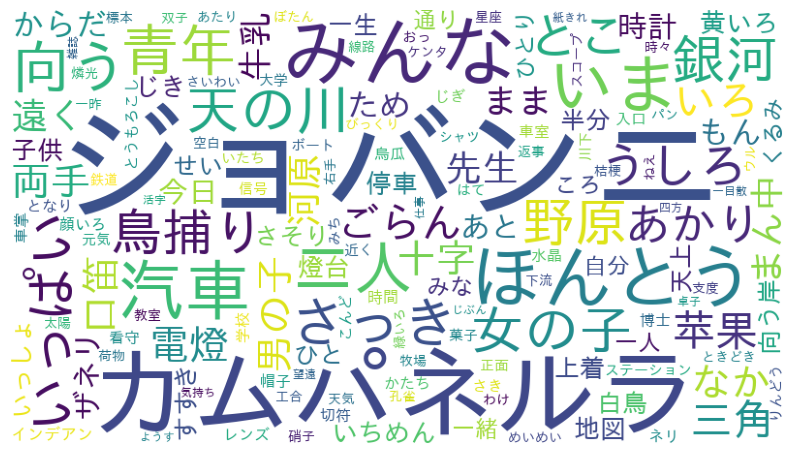

In [3]:
import matplotlib.pyplot as plt
import matplotlib_fontja
from wordcloud import WordCloud

wc = WordCloud(font_path=matplotlib_fontja.get_font_ttf_path(),  # 日本語フォントの指定が必須
               width=800, height=450, background_color="white", max_words=150, colormap="viridis")
wc.generate_from_frequencies(freq)
plt.figure(figsize=(10, 6)); plt.imshow(wc); plt.axis("off"); plt.show()
wc.to_file("wordcloud.png");

- 分かち書き済みの文字列を `wc.generate(text)` に渡す方法もあるが、頻度辞書を渡すほうが品詞やストップワードを制御しやすい。